In [1]:
# Setup for the two UKESM sea-ice checks, without rerunning 01_indices.
# Recomputes Arctic sea-ice area for one member per scenario straight from the files
# (with the current inputs.py/indices.py), so it doesn't depend on the saved monthly file.
import cftime
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from inputs import load_config, expected_files, check_existence, load_member, open_fx, month_index
from indices import seaice_monthly

MODEL, MEMBER = "UKESM1-1", "r1"
cfg = load_config("inputs.yaml")
files = check_existence(expected_files(cfg, models=[MODEL]))
present = files[files.status == "present"]
fx = {(MODEL, n): (None if (d := open_fx(cfg, MODEL, n)) is None else d.load())
      for n in ("areacella", "areacello", "sftlf")}
SCEN_COLOURS = {"ssp245": "0.3", "G6-1.5K-HiLLA": "#0072B2", "G6-1.5K-SAI": "#D55E00"}

series = {}
for scen in ["ssp245", "G6-1.5K-HiLLA", "G6-1.5K-SAI"]:
    r = present[(present.scenario == scen) & (present.role == "seaice")
                & (present.member == MEMBER)].iloc[0]
    da = load_member(r, chunks="auto")[r["var"]]
    area = fx[(MODEL, "areacello" if r.grid_expected == "ocean" else "areacella")]
    s = seaice_monthly(da, area, cfg["choices"])[0]["sia_nh"].compute().reset_coords(drop=True)
    cal = s.time.values[0].calendar
    s = s.assign_coords(time=[cftime.datetime(int(v) // 12, int(v) % 12 + 1, 15, calendar=cal)
                              for v in month_index(s.time)])          # common mid-month stamps
    series[scen] = s
    print(f"{scen:14s} {s.sizes['time']} months, {str(s.time.values[0])[:7]} to {str(s.time.values[-1])[:7]}")

ds_mon = {MODEL: xr.concat(list(series.values()), dim=pd.Index(list(series), name="scenario"))
                   .to_dataset(name="sia_nh").expand_dims(member=[MEMBER])}

ssp245         1032 months, 2015-01 to 2100-12


G6-1.5K-HiLLA  612 months, 2034-01 to 2084-12


G6-1.5K-SAI    612 months, 2034-01 to 2084-12


/tmp/ipykernel_2823/2101776534.py:30: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  ds_mon = {MODEL: xr.concat(list(series.values()), dim=pd.Index(list(series), name="scenario"))


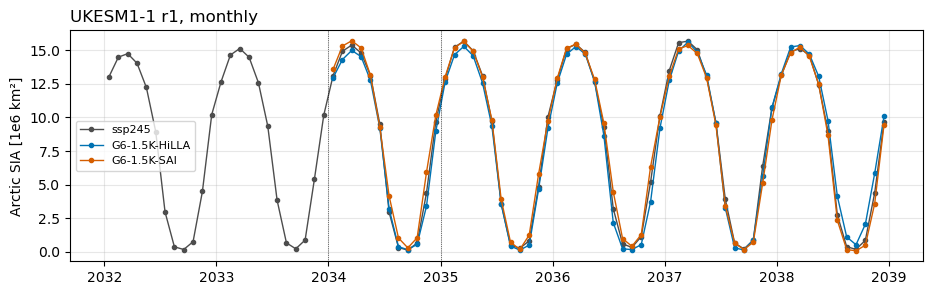

,G6-1.5K-SAI / ssp245,G6-1.5K-HiLLA / ssp245
2034-01,1.036,0.988
2034-02,1.026,0.959
2034-03,1.021,0.974
2034-04,1.026,0.982
2034-05,1.001,0.972
2034-06,0.976,0.970
2034-07,1.410,1.086
2034-08,3.288,1.192
2034-09,2.361,1.234
2034-10,1.604,0.854


In [2]:
# Check 1: UKESM r1 Arctic sea-ice area around the branch point, all scenarios.
# SAI and HiLLA start from the same state as ssp245 r1 in 2034, before deployment, so
# their first months should track ssp245 closely. A step at the start of SAI points to
# the data (time stamps, definition, processing), not the forcing.
m = ds_mon["UKESM1-1"]
fig, ax = plt.subplots(figsize=(11, 3))
for scen in ["ssp245", "G6-1.5K-HiLLA", "G6-1.5K-SAI"]:
    s = m.sia_nh.sel(scenario=scen, member="r1")
    s = s.isel(time=((s.time.dt.year >= 2032) & (s.time.dt.year <= 2038)).values)
    ax.plot([t.year + (t.month - 0.5) / 12 for t in s.time.values], s,
            marker=".", lw=1, color=SCEN_COLOURS[scen], label=scen)
ax.axvline(2034, color="k", lw=0.5, ls=":"); ax.axvline(2035, color="k", lw=0.5, ls=":")
ax.set_ylabel("Arctic SIA [1e6 km²]"); ax.set_title("UKESM1-1 r1, monthly", loc="left")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

# Month-by-month ratio over the first 24 SAI months (1.00 = identical)
tab = {}
for scen in ["G6-1.5K-SAI", "G6-1.5K-HiLLA"]:
    s = m.sia_nh.sel(scenario=scen, member="r1").dropna("time").isel(time=slice(0, 24))
    b = m.sia_nh.sel(scenario="ssp245", member="r1").sel(time=s.time)
    tab[f"{scen} / ssp245"] = (s / b).values.round(3)
tab = pd.DataFrame(tab, index=[f"{t.year}-{t.month:02d}" for t in s.time.values])
tab

In [4]:
# Check 2: SAI vs HiLLA sea-ice fields, cell by cell, in their first common month and
# first common September (same member, both branched from the same ssp245 state).
# If the SAI files hold ice fraction of the SEA part of each cell (UM STASH 0/31) while
# HiLLA holds fraction of the WHOLE cell (CMOR siconca), the SAI/HiLLA ratio will be
# ~1 in open-ocean cells but ~1/sea_fraction in coastal cells, and SAI x sea_fraction
# will match HiLLA.
from inputs import open_parts, time_dim, time_position, month_index
from indices import align_fx, as_fraction

MODEL, MEMBER = "UKESM1-1", "r1"

from inputs import data_var

def member_field(scen):
    r = present[(present.model == MODEL) & (present.scenario == scen)
                & (present.role == "seaice") & (present.member == MEMBER)].iloc[0]
    p = open_parts(r)[0]
    name = data_var(p, [r.file_var, r["var"]])          # name inside the file may differ
    v = p[name]
    t = p[time_dim(p)].values
    print(f"{scen:14s} files={r.n_files}  nc_var={name!r}  first stamps={[str(x)[:16] for x in t[:2]]}  "
          f"bounds position={time_position(p)}  units={v.attrs.get('units')!r}  "
          f"stash={v.attrs.get('um_stash_source')!r}  shape={v.shape[1:]}")
    return load_member(r)[r["var"]]

sai, hil = member_field("G6-1.5K-SAI"), member_field("G6-1.5K-HiLLA")
ym_s, ym_h = list(month_index(sai.time)), list(month_index(hil.time))
common = sorted(set(ym_s) & set(ym_h))
months = [common[0], next(v for v in common if v % 12 == 8)]        # first month, first September

area = align_fx(fx[(MODEL, "areacella")], sai.isel(time=0))
sea = 1 - as_fraction(align_fx(fx[(MODEL, "sftlf")], sai.isel(time=0)))[0]
lat = sai.isel(time=0)[[d for d in sai.dims if "lat" in d][0]]
lat2d = lat.broadcast_like(sai.isel(time=0))
nh = xr.DataArray((lat2d > 0).values, dims=sea.dims)
print("max |lat| difference between SAI and HiLLA files:",
      float(abs(lat.values - hil[[d for d in hil.dims if "lat" in d][0]].values).max()))

rows = []
for ym in months:
    a = as_fraction(sai.isel(time=ym_s.index(ym)))[0]
    b = as_fraction(align_fx(hil.isel(time=ym_h.index(ym)), sai.isel(time=0)))[0]
    a = xr.DataArray(a.values, dims=sea.dims); b = xr.DataArray(b.values, dims=sea.dims)
    label = f"{ym // 12}-{ym % 12 + 1:02d}"
    sia = lambda f: float((f.fillna(0) * area).where(nh, 0).sum()) / 1e12
    rows.append(dict(month=label, cells="NH total SIA [1e6 km2]",
                     SAI=sia(a), HiLLA=sia(b), SAI_x_seafrac=sia(a * sea)))
    icy = nh & ((a.fillna(0) > 0.05) | (b.fillna(0) > 0.05))
    for name, sel in (("open ocean (sea frac = 1)", sea >= 0.999),
                      ("coastal, sea frac 0.5-1", (sea >= 0.5) & (sea < 0.999)),
                      ("coastal, sea frac 0-0.5", (sea > 0) & (sea < 0.5))):
        c = icy & sel
        rows.append(dict(month=label, cells=f"{name} (n={int(c.sum())})",
                         SAI=float(a.where(c).mean()), HiLLA=float(b.where(c).mean()),
                         SAI_x_seafrac=float((a * sea).where(c).mean())))
    rows.append(dict(month=label, cells="NaN cells in field",
                     SAI=int(a.isnull().sum()), HiLLA=int(b.isnull().sum()), SAI_x_seafrac=np.nan))
pd.DataFrame(rows).set_index(["month", "cells"]).round(3)

G6-1.5K-SAI    files=1  nc_var='sea_ice_area_fraction'  first stamps=['2034-01-16 00:00', '2034-02-16 00:00']  bounds position=0.5  units='1'  stash='m01s00i031'  shape=(144, 192)


G6-1.5K-HiLLA  files=3  nc_var='siconca'  first stamps=['2034-01-16 00:00', '2034-02-16 00:00']  bounds position=0.5  units='%'  stash=None  shape=(144, 192)


max |lat| difference between SAI and HiLLA files: 0.0


SAI     HiLLA  SAI_x_seafrac
month   cells                                                                
2034-01 NH total SIA [1e6 km2]                13.595    12.965         11.079
        open ocean (sea frac = 1) (n=2223)     0.933     0.902          0.933
        coastal, sea frac 0.5-1 (n=341)        0.827     0.770          0.653
        coastal, sea frac 0-0.5 (n=329)        0.818     0.781          0.159
        NaN cells in field                  8165.000  8165.000            NaN
2034-09 NH total SIA [1e6 km2]                 0.288     0.150          0.216
        open ocean (sea frac = 1) (n=472)      0.102     0.009          0.102
        coastal, sea frac 0.5-1 (n=59)         0.144     0.157          0.105
        coastal, sea frac 0-0.5 (n=35)         0.301     0.310          0.061
        NaN cells in field                  8165.000  8165.000            NaN

In [5]:
# Check 3: which ssp245 member and month does each SAI / HiLLA run start from?
# Compares each run's FIRST-MONTH sea-ice field with every ssp245 member's field in
# the same calendar month and one year either side. Sea ice keeps its spatial pattern
# for months, so a run branched from ssp245 rN at its start date should be far closer
# to rN in the same month (offset 0) than to any other member or year.
from inputs import month_index
from indices import as_fraction

def seaice_member(scen, member):
    sel = present[(present.scenario == scen) & (present.role == "seaice") & (present.member == member)]
    if sel.empty:
        return None, None
    d = load_member(sel.iloc[0])[sel.iloc[0]["var"]]
    return d, list(month_index(d.time))

def frac(field):
    return as_fraction(field)[0].values      # % or fraction -> fraction

members = cfg["models"][MODEL]["members"]
base = {m: seaice_member("ssp245", m) for m in members}
rows = []
for scen in ["G6-1.5K-HiLLA", "G6-1.5K-SAI"]:
    for m in members:
        d, ym = seaice_member(scen, m)
        if d is None:
            continue
        f = frac(d.isel(time=0))
        for bm, (b, ymb) in base.items():
            for off in (-12, 0, 12):
                if ym[0] + off in ymb:
                    g = frac(b.isel(time=ymb.index(ym[0] + off)))
                    rows.append(dict(run=f"{scen} {m}", start=f"{ym[0] // 12}-{ym[0] % 12 + 1:02d}",
                                     ssp245=bm, offset_months=off,
                                     rms=float(np.sqrt(np.nanmean((f - g) ** 2)))))
res = pd.DataFrame(rows)
best = res.loc[res.groupby("run").rms.idxmin(), ["run", "ssp245", "offset_months", "rms"]]
print("closest ssp245 field to each run's first month:")
print(best.to_string(index=False))
res.pivot_table(index=["run", "start"], columns=["ssp245", "offset_months"], values="rms").round(3)

closest ssp245 field to each run's first month:
             run ssp245  offset_months      rms
G6-1.5K-HiLLA r1     r1              0 0.025733
G6-1.5K-HiLLA r2     r2              0 0.019976
G6-1.5K-HiLLA r3     r3              0 0.017670
  G6-1.5K-SAI r1     r2            -12 0.084752
  G6-1.5K-SAI r2     r2            -12 0.085920
  G6-1.5K-SAI r3     r3              0 0.073068


ssp245                       r1                   r2                   r3  \
offset_months               -12     0      12    -12     0      12    -12   
run              start                                                      
G6-1.5K-HiLLA r1 2034-01  0.096  0.026  0.090  0.083  0.105  0.112  0.100   
G6-1.5K-HiLLA r2 2034-01  0.082  0.103  0.093  0.089  0.020  0.073  0.092   
G6-1.5K-HiLLA r3 2034-01  0.080  0.101  0.080  0.089  0.076  0.086  0.101   
G6-1.5K-SAI r1   2034-01  0.096  0.085  0.087  0.085  0.099  0.106  0.099   
G6-1.5K-SAI r2   2034-01  0.101  0.107  0.100  0.086  0.099  0.104  0.096   
G6-1.5K-SAI r3   2034-01  0.089  0.108  0.091  0.091  0.085  0.088  0.105   

ssp245                                  
offset_months                0      12  
run              start                  
G6-1.5K-HiLLA r1 2034-01  0.103  0.128  
G6-1.5K-HiLLA r2 2034-01  0.075  0.096  
G6-1.5K-HiLLA r3 2034-01  0.018  0.098  
G6-1.5K-SAI r1   2034-01  0.094  0.119  
G6-1.5K-SAI r2   2034-01  0.089  0.095  
G6-1.5K-SAI r3   2034-01  0.073  0.103

In [6]:
# Which source run is mapped to each canonical member, per scenario?
# Prints, for every scenario and member: the member_label used in the paths, the directory
# and files for each variable, any UM suite IDs in the file names (u-xxNNN), and the
# run-identifying global attributes of the first tas file.
import re
from inputs import open_parts

MODEL = "UKESM1-1"
SUITE = re.compile(r"u-[a-z]{2}\d{3}")
ATTRS = re.compile(r"suite|run|variant|parent|branch|source_id|experiment|realization|initiali", re.I)

for scen in ["ssp245", "G6-1.5K-HiLLA", "G6-1.5K-SAI"]:
    print(f"\n=== {MODEL}  {scen}")
    for m in cfg["models"][MODEL]["members"]:
        rows = present[(present.model == MODEL) & (present.scenario == scen) & (present.member == m)]
        if rows.empty:
            print(f"  {m}: no files")
            continue
        print(f"  {m}  ->  member_label = {rows.member_label.iloc[0]}")
        suites = set()
        for _, r in rows.iterrows():
            print(f"     {r.role:7s} {r.files[0].rsplit('/', 1)[0]}/")
            for f in r.files:
                name = f.rsplit("/", 1)[-1]
                suites |= set(SUITE.findall(name))
                print(f"              {name}")
        print(f"     suite IDs in file names: {sorted(suites) if suites else 'none'}")
        r0 = rows[rows.role == "gmsat"].iloc[0] if (rows.role == "gmsat").any() else rows.iloc[0]
        attrs = open_parts(r0)[0].attrs
        hits = {k: str(v)[:150] for k, v in attrs.items() if ATTRS.search(k)}
        print(f"     global attributes ({r0.role} file): {hits if hits else 'none matching'}")


=== UKESM1-1  ssp245
  r1  ->  member_label = r12i1p1f1
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r12i1p1f1/ap5/Amon/tas/
              tas_Amon_UKESM1-0-LL_ssp245_r12i1p1f2_gn_201501-204912.nc
              tas_Amon_UKESM1-0-LL_ssp245_r12i1p1f2_gn_205001-210012.nc
     precip  s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r12i1p1f1/ap5/Amon/pr/
              pr_Amon_UKESM1-0-LL_ssp245_r12i1p1f2_gn_201501-204912.nc
              pr_Amon_UKESM1-0-LL_ssp245_r12i1p1f2_gn_205001-210012.nc
     sst     s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r12i1p1f1/ap5/Amon/ts/
              ts_Amon_UKESM1-0-LL_ssp245_r12i1p1f2_gn_201501-204912.nc
              ts_Amon_UKESM1-0-LL_ssp245_r12i1p1f2_gn_205001-210012.nc
     seaice  s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r12i1p1f1/ap5/SImon/siconca/
              siconca_SImon_UKESM1-0-LL_ssp245_r12i1p1f2_gr_201501-204912.nc
              siconca_SImon_UKESM1-0-LL_ssp245_r12i1p1f2_gr_205001-2100

     global attributes (gmsat file): {'branch_method': 'standard', 'branch_time_in_child': '59400.0', 'branch_time_in_parent': '59400.0', 'experiment': 'update of RCP4.5 based on SSP2', 'experiment_id': 'ssp245', 'initialization_index': '1', 'mo_runid': 'u-dp904', 'parent_activity_id': 'CMIP', 'parent_experiment_id': 'ssp245', 'parent_mip_era': 'CMIP6', 'parent_source_id': 'UKESM1-0-LL', 'parent_time_units': 'days since 1850-01-01', 'parent_variant_label': 'r12i1p1f2', 'realization_index': '12', 'source_id': 'UKESM1-0-LL', 'sub_experiment': 'none', 'sub_experiment_id': 'none', 'variant_label': 'r12i1p1f2'}
  r2  ->  member_label = r2i1p1f1
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r2i1p1f1/ap5/Amon/tas/
              tas_Amon_UKESM1-0-LL_ssp245_r2i1p1f2_gn_201501-204912.nc
              tas_Amon_UKESM1-0-LL_ssp245_r2i1p1f2_gn_205001-210012.nc
     precip  s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r2i1p1f1/ap5/Amon/pr/
              pr_Amon_UKESM1-0-

     global attributes (gmsat file): {'branch_method': 'standard', 'branch_time_in_child': '59400.0', 'branch_time_in_parent': '59400.0', 'experiment': 'update of RCP4.5 based on SSP2', 'experiment_id': 'ssp245', 'initialization_index': '1', 'mo_runid': 'u-dp902', 'parent_activity_id': 'CMIP', 'parent_experiment_id': 'ssp245', 'parent_mip_era': 'CMIP6', 'parent_source_id': 'UKESM1-0-LL', 'parent_time_units': 'days since 1850-01-01', 'parent_variant_label': 'r2i1p1f2', 'realization_index': '2', 'source_id': 'UKESM1-0-LL', 'sub_experiment': 'none', 'sub_experiment_id': 'none', 'variant_label': 'r2i1p1f2'}
  r3  ->  member_label = r3i1p1f1
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r3i1p1f1/ap5/Amon/tas/
              tas_Amon_UKESM1-0-LL_ssp245_r3i1p1f2_gn_201501-204912.nc
              tas_Amon_UKESM1-0-LL_ssp245_r3i1p1f2_gn_205001-210012.nc
     precip  s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r3i1p1f1/ap5/Amon/pr/
              pr_Amon_UKESM1-0-LL_

     global attributes (gmsat file): {'branch_method': 'standard', 'branch_time_in_child': '59400.0', 'branch_time_in_parent': '59400.0', 'experiment': 'update of RCP4.5 based on SSP2', 'experiment_id': 'ssp245', 'initialization_index': '1', 'mo_runid': 'u-dp903', 'parent_activity_id': 'CMIP', 'parent_experiment_id': 'ssp245', 'parent_mip_era': 'CMIP6', 'parent_source_id': 'UKESM1-0-LL', 'parent_time_units': 'days since 1850-01-01', 'parent_variant_label': 'r3i1p1f2', 'realization_index': '3', 'source_id': 'UKESM1-0-LL', 'sub_experiment': 'none', 'sub_experiment_id': 'none', 'variant_label': 'r3i1p1f2'}

=== UKESM1-1  G6-1.5K-HiLLA
  r1  ->  member_label = r12i1p1f2
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r12i1p1f2/apm/Amon/tas/
              tas_Amon_UKESM1-1-LL_g6-1p5-hilla_r12i1p1f2_gn_203401-204912.nc
              tas_Amon_UKESM1-1-LL_g6-1p5-hilla_r12i1p1f2_gn_205001-208411.nc
              tas_Amon_UKESM1-1-LL_g6-1p5-hilla_r12i1p1f2_gn_208401-208

     global attributes (gmsat file): {'branch_method': 'standard', 'branch_time_in_child': '66600.0', 'branch_time_in_parent': '66600.0', 'experiment': 'unknown', 'experiment_id': 'g6-1p5-hilla', 'initialization_index': '1', 'mo_runid': 'u-ds287', 'parent_activity_id': 'unknown', 'parent_experiment_id': 'ssp245', 'parent_mip_era': 'CMIP6', 'parent_source_id': 'UKESM1-1-LL', 'parent_time_units': 'days since 1850-01-01', 'parent_variant_label': 'r12i1p1f2', 'realization_index': '12', 'source_id': 'UKESM1-1-LL', 'sub_experiment': 'none', 'sub_experiment_id': 'none', 'variant_label': 'r12i1p1f2'}
  r2  ->  member_label = r2i1p1f2
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r2i1p1f2/apm/Amon/tas/
              tas_Amon_UKESM1-1-LL_g6-1p5-hilla_r2i1p1f2_gn_203401-204912.nc
              tas_Amon_UKESM1-1-LL_g6-1p5-hilla_r2i1p1f2_gn_205001-208412.nc
              tas_Amon_UKESM1-1-LL_g6-1p5-hilla_r2i1p1f2_gn_208401-208412.nc
     precip  s3://reflective-persisten

     global attributes (gmsat file): {'branch_method': 'standard', 'branch_time_in_child': '66600.0', 'branch_time_in_parent': '66600.0', 'experiment': 'unknown', 'experiment_id': 'g6-1p5-hilla', 'initialization_index': '1', 'mo_runid': 'u-ds275', 'parent_activity_id': 'unknown', 'parent_experiment_id': 'ssp245', 'parent_mip_era': 'CMIP6', 'parent_source_id': 'UKESM1-1-LL', 'parent_time_units': 'days since 1850-01-01', 'parent_variant_label': 'r2i1p1f2', 'realization_index': '2', 'source_id': 'UKESM1-1-LL', 'sub_experiment': 'none', 'sub_experiment_id': 'none', 'variant_label': 'r2i1p1f2'}
  r3  ->  member_label = r3i1p1f2
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r3i1p1f2/apm/Amon/tas/
              tas_Amon_UKESM1-1-LL_g6-1p5-hilla_r3i1p1f2_gn_203401-204912.nc
              tas_Amon_UKESM1-1-LL_g6-1p5-hilla_r3i1p1f2_gn_205001-208411.nc
     precip  s3://reflective-persistent-prod-large/UKESM1-1/G6-1p5K-HiLLA/r3i1p1f2/apm/Amon/pr/
              pr_Amon_

     global attributes (gmsat file): {'branch_method': 'standard', 'branch_time_in_child': '66600.0', 'branch_time_in_parent': '66600.0', 'experiment': 'unknown', 'experiment_id': 'g6-1p5-hilla', 'initialization_index': '1', 'mo_runid': 'u-ds286', 'parent_activity_id': 'unknown', 'parent_experiment_id': 'ssp245', 'parent_mip_era': 'CMIP6', 'parent_source_id': 'UKESM1-1-LL', 'parent_time_units': 'days since 1850-01-01', 'parent_variant_label': 'r3i1p1f2', 'realization_index': '3', 'source_id': 'UKESM1-1-LL', 'sub_experiment': 'none', 'sub_experiment_id': 'none', 'variant_label': 'r3i1p1f2'}

=== UKESM1-1  G6-1.5K-SAI
  r1  ->  member_label = r12i1p1f2
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r12i1p1f2/mon/tas/
              tas_mon_UKESM1-1-LL_G6-1p5K-SAI_u-dp691_203401-208512.nc
     precip  s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r12i1p1f2/mon/pr/
              pr_mon_UKESM1-1-LL_G6-1p5K-SAI_u-dp691_203401-208512.nc
     seaice  s3://r

     global attributes (gmsat file): none matching
  r2  ->  member_label = r2i1p1f2
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r2i1p1f2/mon/tas/
              tas_mon_UKESM1-1-LL_G6-1p5K-SAI_u-dp583_203401-208512.nc
     precip  s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r2i1p1f2/mon/pr/
              pr_mon_UKESM1-1-LL_G6-1p5K-SAI_u-dp583_203401-208512.nc
     seaice  s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r2i1p1f2/mon/siconca/
              siconca_mon_UKESM1-1-LL_G6-1p5K-SAI_u-dp583_203401-208512.nc
     suite IDs in file names: ['u-dp583']


     global attributes (gmsat file): none matching
  r3  ->  member_label = r3i1p1f2
     gmsat   s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r3i1p1f2/mon/tas/
              tas_mon_UKESM1-1-LL_G6-1p5K-SAI_u-dp690_203401-208512.nc
     precip  s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r3i1p1f2/mon/pr/
              pr_mon_UKESM1-1-LL_G6-1p5K-SAI_u-dp690_203401-208512.nc
     seaice  s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r3i1p1f2/mon/siconca/
              siconca_mon_UKESM1-1-LL_G6-1p5K-SAI_u-dp690_203401-208512.nc
     suite IDs in file names: ['u-dp690']


     global attributes (gmsat file): none matching


In [7]:
### test daily values instead: 


# Does u-dp691 (G6-1.5K-SAI r12) branch from u-dp904 (SSP245)?
# Compares the two daily sea-ice files over SAI's first 14 days, matched by actual
# date (not the dates in the file names). A run branched from u-dp904 on its start date
# should be near-identical on day 1 and diverge slowly. Control: SAI day 1 against
# u-dp904 on the same calendar day one year earlier (an unrelated state).
import numpy as np, pandas as pd, xarray as xr
from inputs import open_nc, data_var, time_dim, UNDECLARED_FILL_THRESHOLD
from indices import as_fraction, align_fx

SAI_D = "s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r12i1p1f2/day/seaice/seaice_day_UKESM1-1-LL_u-dp691_201501-210012.nc"
SSP_D = "s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r12i1p1f1/seaice_day_UKESM1-1-LL_u-dp904_201501-210012.nc"
N_DAYS = 14

def open_daily(path):
    ds = open_nc(path)
    v = data_var(ds)
    tdim = time_dim(ds)
    t = ds[tdim].values
    da = ds[v].rename({tdim: "time"})
    print(f"{path.rsplit('/', 1)[-1]}\n   var={v!r} units={da.attrs.get('units')!r} shape={da.shape} "
          f"calendar={t[0].calendar}\n   time {str(t[0])[:16]} .. {str(t[-1])[:16]} ({len(t)} steps)")
    return da

def day_key(time):
    return list((time.dt.year * 10000 + time.dt.month * 100 + time.dt.day).values)

def field(da, i):
    f = da.isel(time=i)
    f = f.where(abs(f) < UNDECLARED_FILL_THRESHOLD)      # undeclared fill values -> NaN
    return as_fraction(f)[0]

sai, ssp = open_daily(SAI_D), open_daily(SSP_D)
ks, kb = day_key(sai.time), day_key(ssp.time)
print(f"\nSAI first day {ks[0]}; present in u-dp904 file: {ks[0] in kb}")

try:
    area = align_fx(fx[(MODEL, "areacella")], sai.isel(time=0)).values
except Exception as e:
    print("areacella does not match the daily grid, SIA column skipped:", e)
    area = None
lat = sai.isel(time=0)[[d for d in sai.dims if "lat" in d][0]]
nh = (lat.broadcast_like(sai.isel(time=0)) > 0).values

def compare(i_s, i_b):
    a, b = field(sai, i_s).values, field(ssp, i_b).values
    d = a - b
    out = dict(rms=float(np.sqrt(np.nanmean(d ** 2))), max_abs=float(np.nanmax(abs(d))),
               identical_cells=f"{100 * np.mean((d == 0)[np.isfinite(d)]):.1f}%")
    if area is not None:
        sia = lambda f: float(np.nansum(np.where(nh, f, 0) * area)) / 1e12
        out.update(SIA_SAI=round(sia(a), 3), SIA_ssp245=round(sia(b), 3))
    return out

rows = []
for i in range(N_DAYS):
    k = ks[i]
    if k in kb:
        rows.append(dict(day=f"{k // 10000}-{k // 100 % 100:02d}-{k % 100:02d}", **compare(i, kb.index(k))))
ctrl = ks[0] - 10000                                       # same calendar day, one year earlier
if ctrl in kb:
    rows.append(dict(day=f"control: SAI day 1 vs u-dp904 {ctrl // 10000}-{ctrl // 100 % 100:02d}-{ctrl % 100:02d}",
                     **compare(0, kb.index(ctrl))))
pd.DataFrame(rows).set_index("day").round(5)

seaice_day_UKESM1-1-LL_u-dp691_201501-210012.nc
   var='sea_ice_area_fraction' units='1' shape=(18360, 144, 192) calendar=360_day
   time 2034-01-01 12:00 .. 2084-12-30 12:00 (18360 steps)


seaice_day_UKESM1-1-LL_u-dp904_201501-210012.nc
   var='sea_ice_area_fraction' units='1' shape=(30960, 144, 192) calendar=360_day
   time 2015-01-01 12:00 .. 2100-12-30 12:00 (30960 steps)

SAI first day 20340101; present in u-dp904 file: True


,rms,max_abs,identical_cells,SIA_SAI,SIA_ssp245
day,,,,,
2034-01-01,0.11605,0.99687,78.7%,12.038,11.838
2034-01-02,0.11552,0.99967,78.7%,12.125,11.930
2034-01-03,0.11343,0.99770,78.7%,12.223,12.013
2034-01-04,0.11126,0.99652,78.8%,12.335,12.085
2034-01-05,0.10952,0.99888,78.8%,12.411,12.131
2034-01-06,0.10831,0.99942,78.8%,12.520,12.261
2034-01-07,0.10828,0.99995,78.8%,12.688,12.387
2034-01-08,0.10824,0.99993,78.8%,12.835,12.475
2034-01-09,0.10904,0.99997,78.8%,12.969,12.569


In [8]:
# Branch check for all UKESM G6-1.5K-SAI members, using the daily sea-ice files.
# Finds the daily files by the r12 layout, then compares each SAI member's FIRST DAY with
# candidate days in EVERY ssp245 daily file found (every 1 January, plus all days within
# 90 days of the SAI start). Metric: RMS over cells where either field has ice.
# A genuine branch point stands out with an RMS near zero, far below the median.
import re
import numpy as np, pandas as pd
from inputs import resolve, open_nc, data_var, time_dim, UNDECLARED_FILL_THRESHOLD
from indices import as_fraction

ROOT = "s3://reflective-persistent-prod-large/UKESM1-1"
SAI_LABELS = cfg["models"]["UKESM1-1"]["scenarios"]["G6-1.5K-SAI"]["member_labels"]
SSP_LABELS = cfg["models"]["UKESM1-1"]["scenarios"]["ssp245"]["member_labels"]
SUITE = re.compile(r"u-[a-z]{2}\d{3}")

def find(pattern):
    hits = [p for p, _ in resolve(pattern)]
    return hits[0] if len(hits) == 1 else (None if not hits else hits)

def daily(path):
    ds = open_nc(path)
    return ds[data_var(ds)].rename({time_dim(ds): "time"})

def field(da, i):
    f = da.isel(time=int(i)).load()
    return as_fraction(f.where(abs(f) < UNDECLARED_FILL_THRESHOLD))[0].values

def day_number(time):          # days since year 0 on a 360-day calendar
    return ((time.dt.year * 12 + time.dt.month - 1) * 30 + time.dt.day - 1).values

def label(path):
    s = SUITE.findall(path.rsplit("/", 1)[-1])
    return s[0] if s else path.rsplit("/", 1)[-1]

# 1. locate files
sai_files = {m: find(f"{ROOT}/G6-1.5K-SAI/{lab}/day/seaice/*.nc") for m, lab in SAI_LABELS.items()}
ssp_files = {m: find(f"{ROOT}/SSP245/{lab}/seaice_day_*.nc") for m, lab in SSP_LABELS.items()}
for kind, fs in (("SAI", sai_files), ("ssp245", ssp_files)):
    for m, f in fs.items():
        print(f"{kind:6s} {m}: {f if f else 'NOT FOUND'}")
sai_files = {m: f for m, f in sai_files.items() if isinstance(f, str)}
ssp_files = {m: f for m, f in ssp_files.items() if isinstance(f, str)}

# 2. first-day fields of each SAI member
targets = {}
for m, f in sai_files.items():
    da = daily(f)
    targets[m] = dict(field=field(da, 0), start=int(day_number(da.time)[0]),
                      date=str(da.time.values[0])[:10], suite=label(f))
    print(f"SAI {m} ({targets[m]['suite']}) starts {targets[m]['date']}")

# 3. scan each ssp245 file once, comparing every candidate day with every SAI target
rows = []
for bm, f in ssp_files.items():
    da = daily(f)
    dn = day_number(da.time)
    jan1 = (da.time.dt.month.values == 1) & (da.time.dt.day.values == 1)
    near = np.zeros(len(dn), bool)
    for t in targets.values():
        near |= abs(dn - t["start"]) <= 90
    cand = np.where(jan1 | near)[0]
    print(f"scanning ssp245 {bm} ({label(f)}): {len(cand)} days ...", flush=True)
    for i in cand:
        g = field(da, i)
        date = str(da.time.values[i])[:10]
        for m, t in targets.items():
            a = t["field"]
            icy = np.isfinite(a) & np.isfinite(g) & ((a > 0) | (g > 0))
            rows.append(dict(sai=f"{m} ({t['suite']})", ssp245=f"{bm} ({label(f)})", date=date,
                             same_date=dn[i] == t["start"],
                             rms=float(np.sqrt(np.mean((a[icy] - g[icy]) ** 2)))))
res = pd.DataFrame(rows)

# 4. summaries
summary = []
for (s, b), g in res.groupby(["sai", "ssp245"]):
    best = g.loc[g.rms.idxmin()]
    same = g[g.same_date]
    summary.append(dict(sai=s, ssp245=b, best_date=best.date, best_rms=best.rms,
                        rms_on_SAI_start=float(same.rms.iloc[0]) if len(same) else np.nan,
                        median_rms=g.rms.median()))
summary = pd.DataFrame(summary).set_index(["sai", "ssp245"]).round(4)
print("\nPer SAI member and ssp245 file: best-matching day, match on the SAI start date, and the median")
summary

SAI    r1: s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r12i1p1f2/day/seaice/seaice_day_UKESM1-1-LL_u-dp691_201501-210012.nc
SAI    r2: s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r2i1p1f2/day/seaice/seaice_day_UKESM1-1-LL_u-dp583_201501-210012.nc
SAI    r3: s3://reflective-persistent-prod-large/UKESM1-1/G6-1.5K-SAI/r3i1p1f2/day/seaice/seaice_day_UKESM1-1-LL_u-dp690_201501-210012.nc
ssp245 r1: s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r12i1p1f1/seaice_day_UKESM1-1-LL_u-dp904_201501-210012.nc
ssp245 r2: s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r2i1p1f1/seaice_day_UKESM1-1-LL_u-dp902_201501-210012.nc
ssp245 r3: s3://reflective-persistent-prod-large/UKESM1-1/SSP245/r3i1p1f1/seaice_day_UKESM1-1-LL_u-dp903_201501-210012.nc


SAI r1 (u-dp691) starts 2034-01-01


SAI r2 (u-dp583) starts 2034-01-01


SAI r3 (u-dp690) starts 2034-01-01


scanning ssp245 r1 (u-dp904): 266 days ...


scanning ssp245 r2 (u-dp902): 266 days ...


scanning ssp245 r3 (u-dp903): 266 days ...



Per SAI member and ssp245 file: best-matching day, match on the SAI start date, and the median


best_date  best_rms  rms_on_SAI_start  median_rms
sai          ssp245                                                          
r1 (u-dp691) r1 (u-dp904)  2031-01-01    0.2171            0.2515      0.3540
             r2 (u-dp902)  2020-01-01    0.2158            0.2397      0.3639
             r3 (u-dp903)  2044-01-01    0.2226            0.2451      0.3681
r2 (u-dp583) r1 (u-dp904)  2030-01-01    0.2051            0.2508      0.3097
             r2 (u-dp902)  2030-01-01    0.1970            0.2620      0.3151
             r3 (u-dp903)  2029-01-01    0.2019            0.2423      0.3265
r3 (u-dp690) r1 (u-dp904)  2027-01-01    0.2166            0.2599      0.3340
             r2 (u-dp902)  2025-01-01    0.2093            0.2151      0.3317
             r3 (u-dp903)  2034-01-09    0.2035            0.2262      0.3356